In [2]:
import os
import sys

sys.path.append(os.path.abspath('..'))

import torch
from src.losses import ComboLoss

criterion = ComboLoss()

# Dummy batch of 2 images, 4 channels, 128x800
dummy_logits = torch.randn(2, 4, 128, 800, requires_grad=True)
dummy_targets = torch.zeros(2, 4, 128, 800)  # clean images test
dummy_targets[0, 2, 20:50, 100:200] = 1.0  # add one defect

loss = criterion(dummy_logits, dummy_targets)
loss.backward()  # Test that gradients compute without error

print(f"Computed Loss: {loss.item():.4f}")
print("Gradients successfully calculated!")


Computed Loss: 1.7979
Gradients successfully calculated!


In [3]:
import os
import sys

sys.path.append(os.path.abspath('..'))

import numpy as np
from src.metrics import compute_competition_metrics, post_process_mask
import torch

print("=== 1. Testing post_process_mask ===")
# Create a dummy mask for 4 classes: shape (4, 128, 800)
sample_mask = np.zeros((4, 128, 800), dtype=np.uint8)

# Class 0 (defect_a, threshold=15):
# Add a blob of area 20 (>=15, should KEEP) and a tiny speckle of area 5 (<15, should REMOVE)
sample_mask[0, 10:15, 10:14] = 1  # 5x4 = 20 pixels
sample_mask[0, 50:51, 50:55] = 1  # 1x5 = 5 pixels

# Class 1 (defect_b, threshold=50):
# Add a blob of area 60 (>=50, should KEEP) and a blob of area 30 (<50, should REMOVE)
sample_mask[1, 20:26, 20:30] = 1  # 6x10 = 60 pixels
sample_mask[1, 70:73, 70:80] = 1  # 3x10 = 30 pixels

clean_mask = post_process_mask(sample_mask)

print(
    f"Class 0 (defect_a): Original = {sample_mask[0].sum()} px -> Cleaned ="
    f" {clean_mask[0].sum()} px (Expected: 20)"
)
print(
    f"Class 1 (defect_b): Original = {sample_mask[1].sum()} px -> Cleaned ="
    f" {clean_mask[1].sum()} px (Expected: 60)"
)

assert clean_mask[0].sum() == 20, "Class 0 filter error!"
assert clean_mask[1].sum() == 60, "Class 1 filter error!"
print("✅ post_process_mask passed all tests!\n")


print("=== 2. Testing compute_competition_metrics with Torch Tensors ===")
# Create dummy predictions and ground truth: (Batch=2, Channels=4, 128, 800)
dummy_logits = torch.randn(2, 4, 128, 800)
dummy_targets = torch.zeros(2, 4, 128, 800)
# Add a real defect to image 0, channel 2 (defect_c)
dummy_targets[0, 2, 30:70, 200:300] = 1.0

# Compute competition metrics
results = compute_competition_metrics(
    dummy_logits, dummy_targets, threshold=0.5
)

for k, v in results.items():
  print(f"{k}: {v:.4f}")

print("✅ compute_competition_metrics passed without error!")


=== 1. Testing post_process_mask ===
Class 0 (defect_a): Original = 25 px -> Cleaned = 20 px (Expected: 20)
Class 1 (defect_b): Original = 90 px -> Cleaned = 60 px (Expected: 60)
✅ post_process_mask passed all tests!

=== 2. Testing compute_competition_metrics with Torch Tensors ===
foreground_dice: 0.0719
false_positive_score: 0.4991
empty_accuracy: 0.0000
official_score: 0.1501
✅ compute_competition_metrics passed without error!


In [17]:
import importlib
import src.inference
importlib.reload(src.inference)
from src.inference import generate_submission


# Test on 16 images
generate_submission(
    sample_sub_csv='../data/sample_submission.csv',
    test_image_dir='../data/test',
    checkpoint_path='../models/best_scratch_unet.pth',
    output_csv='../submission.csv',
    sample_limit=16,
    batch_size=8
)



Running inference on device: cpu
Using local checkpoint: ../models/best_scratch_unet.pth
Total test images to predict: 3000
Limited to 16 images for fast testing
Loaded weights from ../models/best_scratch_unet.pth


Generating Predictions: 100%|██████████| 2/2 [06:51<00:00, 205.75s/it]



✅ Submission successfully saved to: ../submission.csv
Submission Shape: (64, 4) (Expected: (12000, 4))
Detected Defect Rows: 10 / 64 (15.62%)
Clean Rows: 54


## Visual Error Analysis

### 1. Step 1: Alpha-Blending Helper

In [13]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch

# Distinct color palette for defect visualization (RGB)
CLASS_COLORS = {
    0: (255, 215, 0),    # defect_a: Gold / Yellow
    1: (0, 255, 255),    # defect_b: Cyan
    2: (255, 0, 255),    # defect_c: Magenta
    3: (255, 69, 0),     # defect_d: Red-Orange
}

def overlay_mask(image_rgb, mask_2d, color=(255, 0, 0), alpha=0.5):
    """Overlays a binary 2D mask on an RGB image with transparency."""
    overlay = image_rgb.copy()
    if mask_2d.sum() == 0:
        return overlay
    
    colored_mask = np.zeros_like(image_rgb)
    colored_mask[mask_2d > 0] = color
    
    # Blend: image * (1 - alpha) + mask * alpha
    blended = np.where(
        np.expand_dims(mask_2d, axis=-1) > 0,
        (image_rgb * (1.0 - alpha) + colored_mask * alpha).astype(np.uint8),
        image_rgb
    )
    return blended


### 2. Error Categorization Engine

In [14]:
from src.dataset import SurfaceDefectDataset, get_stratified_split
from src.model import ScratchUNet
from src.metrics import post_process_mask
import pandas as pd

# 1. Load validation data & model
df = pd.read_csv('../data/train.csv')
_, val_df = get_stratified_split(df, val_size=0.20, random_state=42)
val_dataset = SurfaceDefectDataset(val_df, image_dir='../data/train')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = ScratchUNet(in_channels=3, out_channels=4).to(device)
model.load_state_dict(torch.load('../models/best_scratch_unet.pth', map_location=device))
model.eval()


ScratchUNet(
  (enc1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momen

### Step 3: The 4-Panel Plot Function

In [15]:
def plot_diagnostic_sample(image_tensor, gt_mask_tensor, model, threshold=0.5):
    """
    Plots:
    1. Raw Image
    2. Ground Truth Mask (Green)
    3. Model Sigmoid Heatmap (Hot colormap)
    4. Post-Processed Prediction (Red)
    """
    # Prepare NumPy image (H, W, 3) in [0, 255]
    img_np = (image_tensor.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    
    # Model forward pass
    with torch.no_grad():
        input_tensor = image_tensor.unsqueeze(0).to(device)
        logits = model(input_tensor)
        probs = torch.sigmoid(logits)[0].cpu().numpy()  # (4, 128, 800)
    
    preds_bin = (probs > threshold).astype(np.uint8)
    clean_preds = post_process_mask(preds_bin)
    gt_np = gt_mask_tensor.numpy().astype(np.uint8)
    
    DEFECT_NAMES = ['defect_a', 'defect_b', 'defect_c', 'defect_d']
    
    # For each class present in GT or Prediction:
    active_classes = [c for c in range(4) if gt_np[c].sum() > 0 or clean_preds[c].sum() > 0]
    if not active_classes:
        active_classes = [0]  # If completely clean, show class 0
        
    for c in active_classes:
        fig, axes = plt.subplots(4, 1, figsize=(15, 6))
        
        # 1. Raw Steel Image
        axes[0].imshow(img_np)
        axes[0].set_title(f"1. Original Steel Surface [{DEFECT_NAMES[c]}]", fontsize=11, fontweight='bold')
        axes[0].axis('off')
        
        # 2. Ground Truth (Green)
        gt_overlay = overlay_mask(img_np, gt_np[c], color=(0, 255, 0), alpha=0.6)
        axes[1].imshow(gt_overlay)
        axes[1].set_title(f"2. Ground Truth (Pixels: {gt_np[c].sum()})", fontsize=11, color='green', fontweight='bold')
        axes[1].axis('off')
        
        # 3. Model Probability Heatmap
        heatmap = axes[2].imshow(probs[c], cmap='inferno', vmin=0.0, vmax=1.0)
        axes[2].set_title(f"3. Raw Sigmoid Heatmap (Max Conf: {probs[c].max():.2f})", fontsize=11, color='purple', fontweight='bold')
        axes[2].axis('off')
        plt.colorbar(heatmap, ax=axes[2], fraction=0.015, pad=0.02)
        
        # 4. Final Cleaned Prediction (Red)
        pred_overlay = overlay_mask(img_np, clean_preds[c], color=(255, 0, 0), alpha=0.6)
        axes[3].imshow(pred_overlay)
        axes[3].set_title(f"4. Final Prediction (Pixels: {clean_preds[c].sum()})", fontsize=11, color='red', fontweight='bold')
        axes[3].axis('off')
        
        plt.tight_layout()
        plt.show()

### The Test Cell: Find & Inspect 1 Defective and 1 Clean Sample

🔬 === INSPECTING DEFECTIVE SAMPLE (Index 0) ===


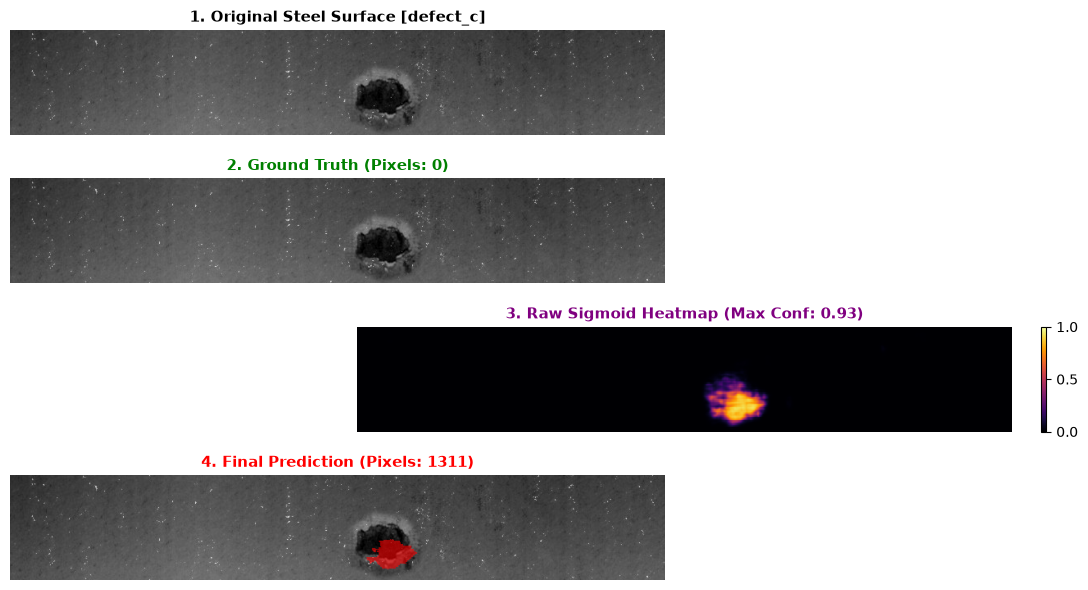

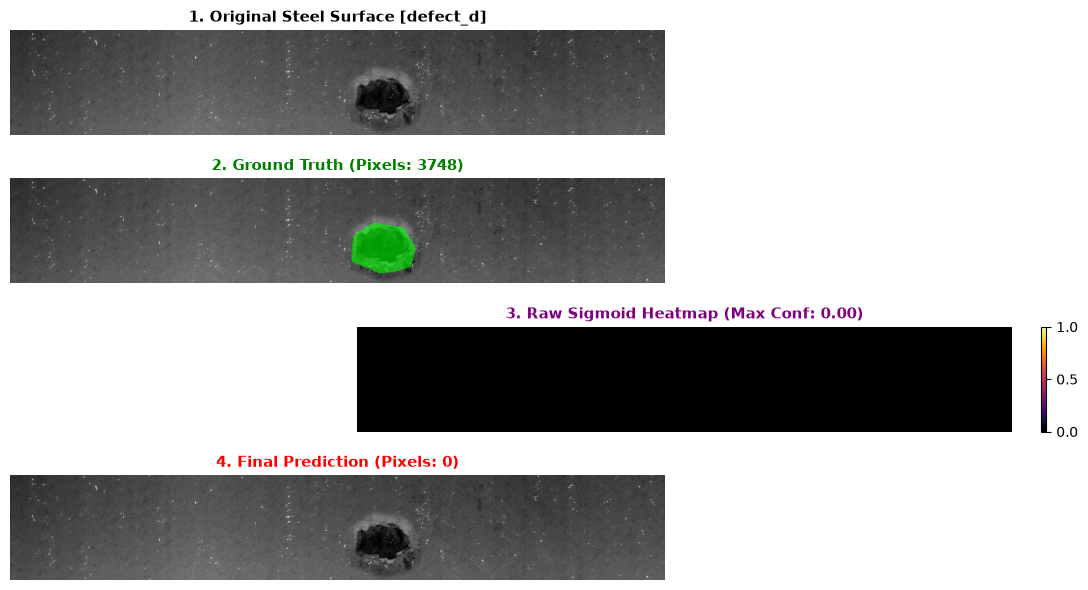

🔬 === INSPECTING CLEAN STEEL SAMPLE (Index 2) ===


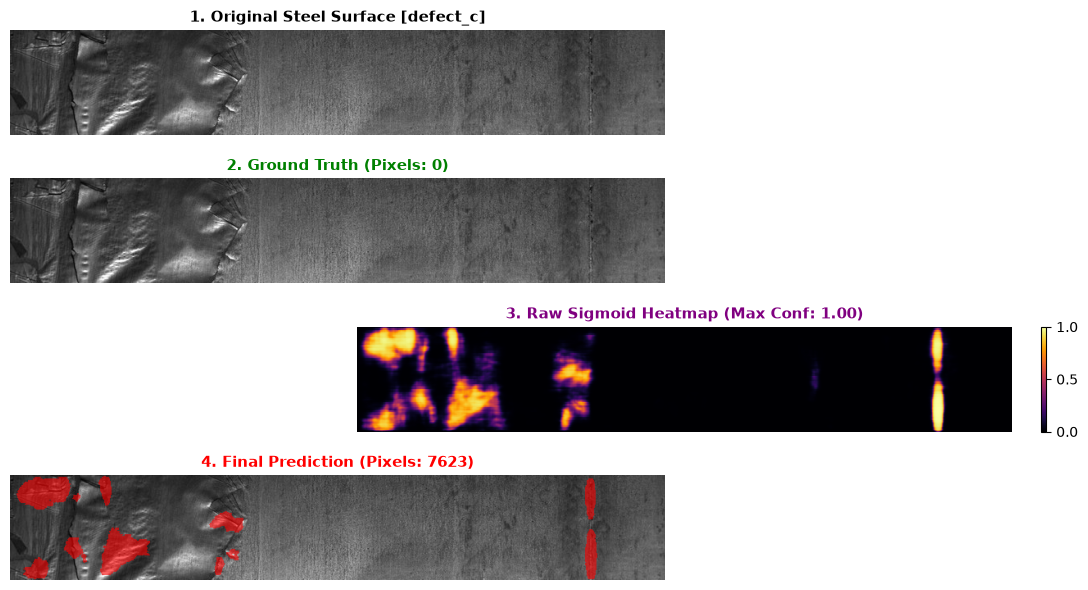

In [16]:
# Search the validation set for:
# 1. A defective sample (to see if the model catches it)
# 2. A clean sample (to see if the model avoids false alarms)

found_defect = False
found_clean = False

for i in range(len(val_dataset)):
    img_tensor, mask_tensor = val_dataset[i]
    is_defective = mask_tensor.sum() > 0

    # 1. Test Defective Sample
    if is_defective and not found_defect:
        print(f"🔬 === INSPECTING DEFECTIVE SAMPLE (Index {i}) ===")
        plot_diagnostic_sample(img_tensor, mask_tensor, model, threshold=0.5)
        found_defect = True

    # 2. Test Clean Sample
    if not is_defective and not found_clean:
        print(f"🔬 === INSPECTING CLEAN STEEL SAMPLE (Index {i}) ===")
        plot_diagnostic_sample(img_tensor, mask_tensor, model, threshold=0.5)
        found_clean = True

    if found_defect and found_clean:
        break
